In [2]:
!pip install -r requirements.txt
!python -m src.run_experiment --weights pretrained

ERROR: Could not open requirements file: [Errno 2] No such file or directory: 'requirements.txt'
/usr/bin/python3: Error while finding module specification for 'src.run_experiment' (ModuleNotFoundError: No module named 'src')



# Milestone 01: Image Feature Extraction Using ResNet18

## Research Background

This experiment is part of an ongoing research project on Nepali Image Caption Generation Using Reformer.

The overall research aims to develop an image captioning system that can generate meaningful descriptions in the Nepali language. The proposed architecture combines a CNN-based image encoder with a Reformer-based language generation model.

## Objective of This Experiment

The goal of this preliminary experiment is to explore how a pretrained ResNet18 model extracts visual features from images.

Specifically, this experiment will:

1. Load and preprocess sample images.
2. Extract visual embeddings using pretrained ResNet18.
3. Examine the dimensions and characteristics of the embeddings.
4. Compare embeddings from different images.
5. Document observations and limitations.

This milestone focuses only on image feature extraction. Nepali caption generation and Reformer integration are planned for later stages.


In [3]:

# Importing required libraries

from pathlib import Path
import sys
import torch
import torchvision
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

# Locating the project directory
cwd = Path.cwd().resolve()
ROOT = cwd.parent if cwd.name == "notebooks" else cwd

# Displaying environment information
print("Project directory:", ROOT)
print("Python version:", sys.version.split()[0])
print("PyTorch version:", torch.__version__)
print("TorchVision version:", torchvision.__version__)
print("CUDA available:", torch.cuda.is_available())


Project directory: /content
Python version: 3.13.18
PyTorch version: 2.14.1+cpu
TorchVision version: 0.29.1+cpu
CUDA available: False



## 2. Loading and Visualizing Sample Images

### Objective

The first stage of image feature extraction involves loading and examining sample images.

For this preliminary experiment, two images will be used to explore how a pretrained ResNet18 encoder represents visual information.

Visual inspection helps confirm that the images are loaded correctly before applying preprocessing and feature extraction.

The images will later be converted into numerical embeddings using the ResNet18 architecture.


Upload astronaut.png


Saving astronaut.png to astronaut (2).png
Upload chelsea.png


Saving chelsea.png to chelsea.png


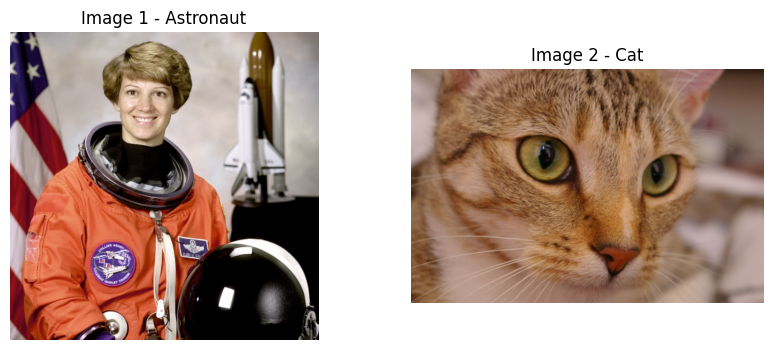

Both images loaded successfully.


In [6]:

# Load and display two images

from google.colab import files
from PIL import Image
import matplotlib.pyplot as plt

# Upload first image
print("Upload astronaut.png")
uploaded1 = files.upload()
image1 = Image.open(list(uploaded1.keys())[0]).convert("RGB")

# Upload second image
print("Upload chelsea.png")
uploaded2 = files.upload()
image2 = Image.open(list(uploaded2.keys())[0]).convert("RGB")

# Display both images
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(image1)
plt.title("Image 1 - Astronaut")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(image2)
plt.title("Image 2 - Cat")
plt.axis("off")

plt.show()

print("Both images loaded successfully.")



## 3. Image Preprocessing

Before extracting image features, both images need to be preprocessed.

Since the images have different sizes, we use the preprocessing transformations associated with the pretrained ResNet18 model.

The preprocessing steps include:

1. Resizing and cropping the images to 224 × 224 pixels.
2. Converting the images into PyTorch tensors.
3. Normalizing pixel values using ImageNet statistics.

These steps help prepare the images for feature extraction using ResNet18.


In [7]:

# Preprocessing images for ResNet18

from torchvision.models import ResNet18_Weights

# Now I use the preprocessing required by pretrained ResNet18
weights = ResNet18_Weights.DEFAULT
preprocess = weights.transforms()


tensor1 = preprocess(image1)
tensor2 = preprocess(image2)


tensor1 = tensor1.unsqueeze(0)
tensor2 = tensor2.unsqueeze(0)

print("Astronaut image shape:", tensor1.shape)
print("Cat image shape:", tensor2.shape)


Astronaut image shape: torch.Size([1, 3, 224, 224])
Cat image shape: torch.Size([1, 3, 224, 224])



## 4. Image Feature Extraction Using ResNet18

ResNet18 is a convolutional neural network commonly used for image classification.

In this experiment, we use a pretrained ResNet18 model as a feature extractor rather than a classifier.

The original classification layer is removed so that the model produces a numerical representation of each image.

These image embeddings will help us explore how visual information can later be passed to the Reformer-based language generation model.


In [8]:

import torch.nn as nn
from torchvision.models import resnet18, ResNet18_Weights

model = resnet18(weights=ResNet18_Weights.DEFAULT)

# Removing final classification layer
model.fc = nn.Identity()

# Setting model to evaluation mode
model.eval()

print("ResNet18 loaded successfully.")
print("Final layer:", model.fc)


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 147MB/s]

ResNet18 loaded successfully.
Final layer: Identity()


In [9]:

# Extracting image features using ResNet18

with torch.no_grad():
    embedding1 = model(tensor1)
    embedding2 = model(tensor2)

print("Astronaut embedding:", embedding1.shape)
print("Cat embedding:", embedding2.shape)


Astronaut embedding: torch.Size([1, 512])
Cat embedding: torch.Size([1, 512])



### Observation

The pretrained ResNet18 model was used to extract visual features from two sample images: an astronaut and a cat.

The final classification layer was removed to obtain image embeddings instead of classification predictions.

Each image was represented by a 512-dimensional feature vector.

This experiment demonstrates the initial image encoding stage of the proposed Nepali image captioning system. Integration with the Reformer language model remains future work.



## 5. Comparing Image Embeddings

After extracting image features, I wanted to compare the embeddings generated for the two sample images.

For this experiment, I used cosine similarity to measure how closely the two feature vectors are aligned.

Cosine similarity measures the angle between two vectors rather than comparing their individual values.

A higher similarity score indicates that the vectors point in similar directions, while a lower score indicates less alignment.

This comparison helps explore how ResNet18 represents different images.


In [10]:

# Compare image embeddings

import torch.nn.functional as F

similarity = F.cosine_similarity(embedding1, embedding2)

print("Cosine similarity:", round(similarity.item(), 4))


Cosine similarity: 0.5303



### Observation

I compared the 512-dimensional embeddings of the astronaut and cat images using cosine similarity.

The cosine similarity score was 0.5303
This experiment provided an initial comparison of the visual representations extracted by pretrained ResNet18.

However, comparing only two images is not enough to determine whether the encoder is suitable for Nepali image caption generation. A larger image dataset and further evaluation will be needed.



## 6. Visualizing Image Embeddings

After comparing the image embeddings using cosine similarity, I wanted to examine their feature values.

Each image is represented by 512 numerical features extracted using pretrained ResNet18.

In this experiment, I plotted the first 50 features of both images to observe differences in their representations.

This visualization provides a basic understanding of the extracted features before integrating them with the Reformer language model.


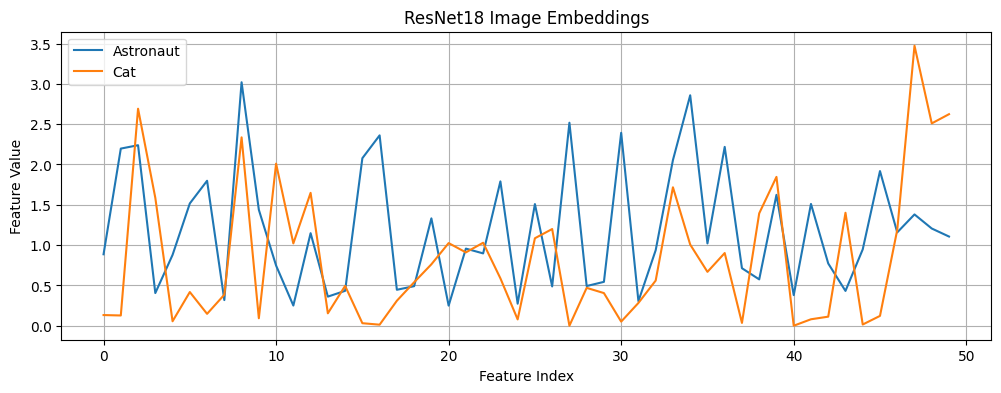

In [11]:

# Converting embeddings to NumPy arrays
features1 = embedding1.squeeze().numpy()
features2 = embedding2.squeeze().numpy()

plt.figure(figsize=(12, 4))

plt.plot(features1[:50], label="Astronaut")
plt.plot(features2[:50], label="Cat")

plt.title("ResNet18 Image Embeddings")
plt.xlabel("Feature Index")
plt.ylabel("Feature Value")
plt.legend()
plt.grid(True)

plt.show()



### Observation

I visualized the first 50 features extracted from the astronaut and cat images using pretrained ResNet18.

The graph shows the numerical feature values generated for each image.

Although both embeddings have the same dimensions, their feature values can differ depending on the visual information present in each image.

However, individual feature values are not directly interpretable as specific objects or visual concepts.

This visualization is exploratory and does not establish the quality of the embeddings for image caption generation.



## 7. Experimental Results

In this experiment, I tested pretrained ResNet18 using two sample images: an astronaut and a cat.

Both images were preprocessed into tensors of shape [1, 3, 224, 224].

After removing the final classification layer, ResNet18 generated a 512-dimensional embedding for each image.

I also compared the embeddings using cosine similarity and visualized the first 50 feature values.

The experiment confirms that the pretrained ResNet18 model can extract numerical image representations that could be explored for use in the proposed captioning system.


In [12]:

from pathlib import Path
import torch.nn.functional as F

similarity = F.cosine_similarity(embedding1, embedding2).item()

results = f"""
ResNet18 Image Feature Extraction
---------------------------------
Model: Pretrained ResNet18
Image 1: Astronaut
Image 2: Cat

Input image shape: {list(tensor1.shape)}
Astronaut embedding: {list(embedding1.shape)}
Cat embedding: {list(embedding2.shape)}

Cosine similarity: {similarity:.4f}
"""

Path("encoder_results.txt").write_text(results)

print(results)
print("Results saved successfully.")



ResNet18 Image Feature Extraction
---------------------------------
Model: Pretrained ResNet18
Image 1: Astronaut
Image 2: Cat

Input image shape: [1, 3, 224, 224]
Astronaut embedding: [1, 512]
Cat embedding: [1, 512]

Cosine similarity: 0.5303

Results saved successfully.



## 8. Limitations

This experiment has several limitations.

First, I used only two sample images, so the results cannot represent the performance of the encoder on a larger dataset.

Second, ResNet18 was pretrained on ImageNet for image classification rather than image caption generation.

Third, cosine similarity only measures the alignment between the extracted feature vectors. It does not measure caption accuracy or semantic understanding.

Finally, this experiment focuses only on image feature extraction. The Reformer decoder has not yet been integrated or trained to generate Nepali captions.

## 9. Future Work

The next stages of this research will focus on:

1. Testing additional CNN-based image encoders.
2. Exploring how image embeddings can be integrated with the Reformer model.
3. Preparing a Nepali image-caption dataset.
4. Training and evaluating the caption generation model.
5. Comparing its performance and computational efficiency with baseline models.



## 10. Conclusion

In this preliminary experiment, I explored image feature extraction using a pretrained ResNet18 model as part of the ongoing Nepali Image Caption Generation Using Reformer research project.

I tested the model using two sample images: an astronaut and a cat. Both images were preprocessed and passed through ResNet18 after removing its final classification layer.

The model successfully generated a 512-dimensional embedding for each image. I also used cosine similarity to compare the embeddings and visualized their first 50 feature values.

This experiment helped me understand how CNN-based encoders convert images into numerical representations.

Although this is only an initial experiment, it establishes a working image feature-extraction pipeline that can be explored for the proposed Nepali image captioning system.

Future work will involve testing other encoders, investigating how image embeddings can be passed to the Reformer model, and evaluating Nepali caption generation.

The complete image captioning system has not yet been implemented.
